# EEI-303 – Processamento de Voz e Áudio

## 24202631372 - Matheus Costa Damasceno

---

# Aula 14 - Laboratório 5 - Janelamento do sinal de voz e Detector de atividade vocal (VAD)

As atividades deverão ser realizadas no ambiente COLAB ou em Jupyter Notebook.

In [1]:
import scipy.signal as signal
import numpy as np
import scipy
import matplotlib.pyplot as plt
import librosa
import math
from pylab import *
from IPython.display import Audio
from librosa.display import specshow

In [2]:
 #Plot frequency and phase response - adaptado de http://mpastell.com/pweave/_downloads/FIR_design_rst.html
def mfreqz(b,a=1,fs=44100):
    w,h = signal.freqz(b,a)
    h_dB = 20 * np.log10 (abs(h))
    plot(w/max(w)*fs/2,h_dB)
    ylabel('Amplitude')
    xlabel(r'Frequency [Hz]')
    title(r'Frequency response')
    plt.grid(True)


In [3]:
import os, urllib.request

REPO_RAW = "https://raw.githubusercontent.com/Mathcd/2026-3-Processamento-de-Voz-e-Audio/main/2-ExerciciosComputacionais/Audios/"

def caminho_audio(nome):
    """Usa o áudio local se existir; senão baixa do GitHub (ex.: no Colab)."""
    caminho = os.path.join("Audios", nome)
    if not os.path.exists(caminho):
        os.makedirs("Audios", exist_ok=True)
        urllib.request.urlretrieve(REPO_RAW + nome, caminho)
    return caminho

O detector de atividade vocal (VAD, do inglês *Voice Actitivity Detection*) é um dos elementos principais na codificação de sinais de voz, responsável pela identificação de trechos do sinal onde há potencial atividade vocal.

Apenas trechos contendo sinal de voz serão codificados e trechos que não contêm sinal de voz ("silêncio") não são codificados, economizando recursos.

Esta atividade tem como principal objetivo elaborar um código que seja capaz de realizar as seguintes tarefas:
1. "quebrar" um sinal de áudio em pequenos trechos (*framing*), com sobreposição de 50% e aplicar uma janela de Hanning;
2. classificar cada um dos trechos em "voz (1)" e "silêncio (0)";

Para classificar o sinal de voz, você poderá utilizar a técnica baseada em limiar de amplitude e/ou na técnica baseada em limiar de energia.

A técnica baseada em limiar de amplitude consiste em obter o valor máximo do valor absoluto da amplitude do sinal naquele trecho. Caso este valor seja maior do que um limiar pré-estabelecido então o trecho é considerado como "voz". Caso contrário, como "silêncio".

A técnica baseada em energia consiste em calcular a energia do trecho do sinal de voz. Caso este valor seja maior do que um limiar pré-estabelecido então o trecho é considerado como "voz". Caso contrário, como "silêncio".

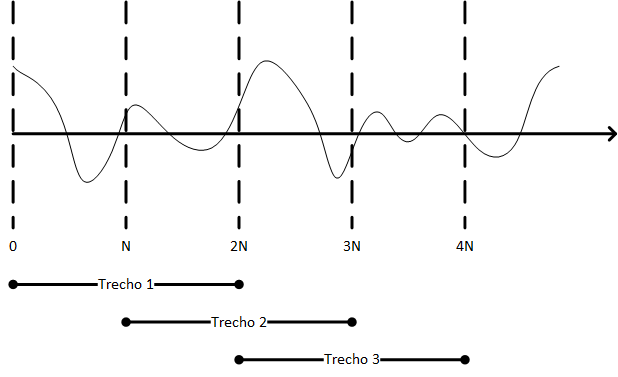

Figura 1. Ilustração de um *framing* de um sinal de áudio, em trechos de tamanho 2N com 50% de sobreposição.

Para mais informações, acesse:
1. https://speechprocessingbook.aalto.fi/Representations/Windowing.html

2. https://speechprocessingbook.aalto.fi/Recognition/Voice_activity_detection.html?highlight=vad

---

# Atividades a serem realizadas:
1. Grave um sinal de voz curto, com palavras que contenham algumas consoantes surdas ou não vozeadas como: /p/, /f/, /t/, /s/, /x/, /k/. Para isso vocês podem utilizar o gravador de som do celular.

A frase gravada foi o trecho de uma música da banda Rosa de Saron: Casino Boulevard. Ela apresenta uma variabilidade de sons de consoantes não vozeadas, como /s/, /t/, /p/, /k/. Transcrição a seguir:

---

O LANCE ESTÁ NO AR

É SÓ VOCÊ GRITAR

BEM ALTO ALTO

MAS SE PREPARE PREPARE

PORQUE NADA NO MUNDO É DE GRAÇA

VOCÊ PODE ATÉ TER MEDO

MAS ANDE CAMINHE

E SÓ NÃO PARE NÃO PARE

---


In [4]:
sr = 44100
audio_sample, fs = librosa.load(caminho_audio('matheus_celular.wav'), sr=sr)

In [5]:
Audio(data=audio_sample, rate=sr) # Reproduzindo o sinal de voz

In [6]:
fs = 8000
audio_resample = librosa.resample(audio_sample, orig_sr=sr, target_sr=fs)

In [7]:
Audio(data=audio_resample, rate=fs) # Reproduzindo o sinal de voz reamostrado

In [8]:
T = len(audio_resample) # Obtendo o número de amostras do sinal de voz
audio_resample = audio_resample - mean(audio_resample) # removendo a média do sinal, para que o sinal resultante tenha média nula
print(T)

171520


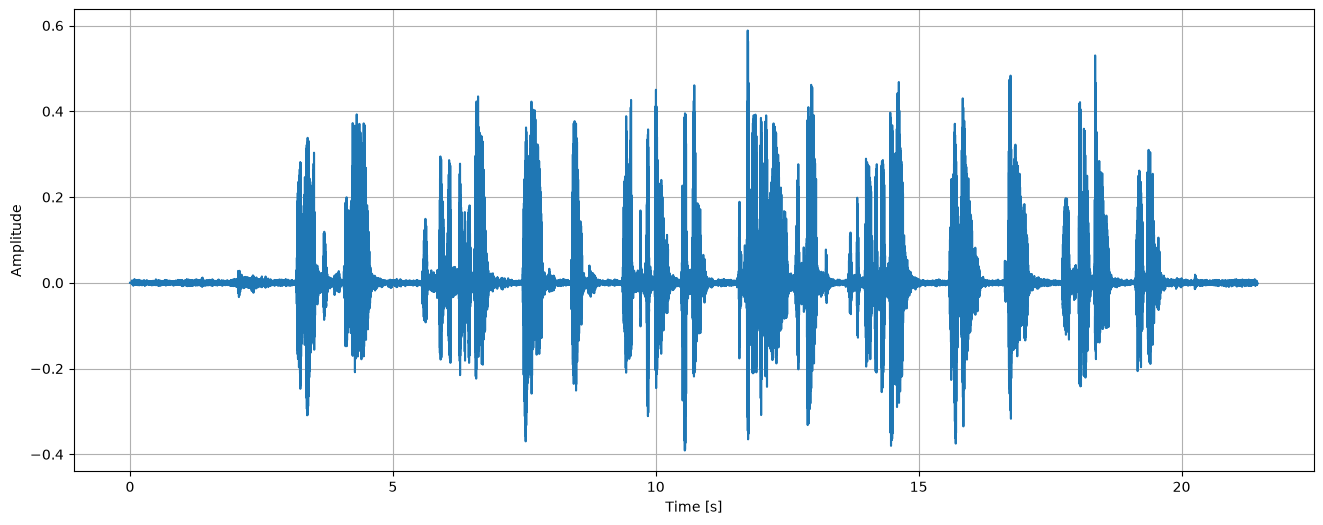

In [9]:
# Plotando o sinal de voz em função do tempo
t  = np.linspace(0,T/fs,T, endpoint=False)
n  = np.linspace(0,T,T, endpoint=False)
plt.figure(figsize=(16,6))
plot(t,audio_resample)
ylabel('Amplitude')
xlabel('Time [s]')
plt.grid(True)

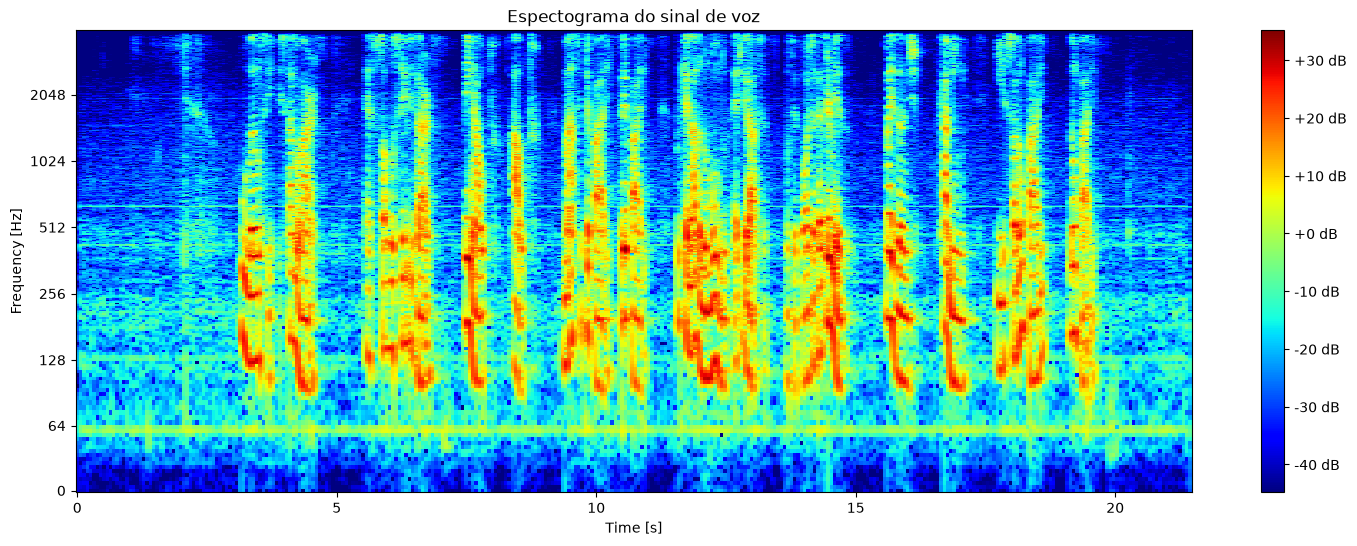

In [10]:
# Obtendo o espectograma do sinal de voz
audio_stft_s = np.abs(librosa.stft(audio_resample))

plt.figure(figsize=(18,6))
specshow(librosa.amplitude_to_db(audio_stft_s),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Espectograma do sinal de voz')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.colorbar(format='%+2.0f dB')

2. Para este sinal gravado, elabore um código que seja capaz de quebrar este sinal em trechos em pequenos trechos (*framing*), com duração de 20 ms, com sobreposição de 50% e aplicar uma janela de Hanning.

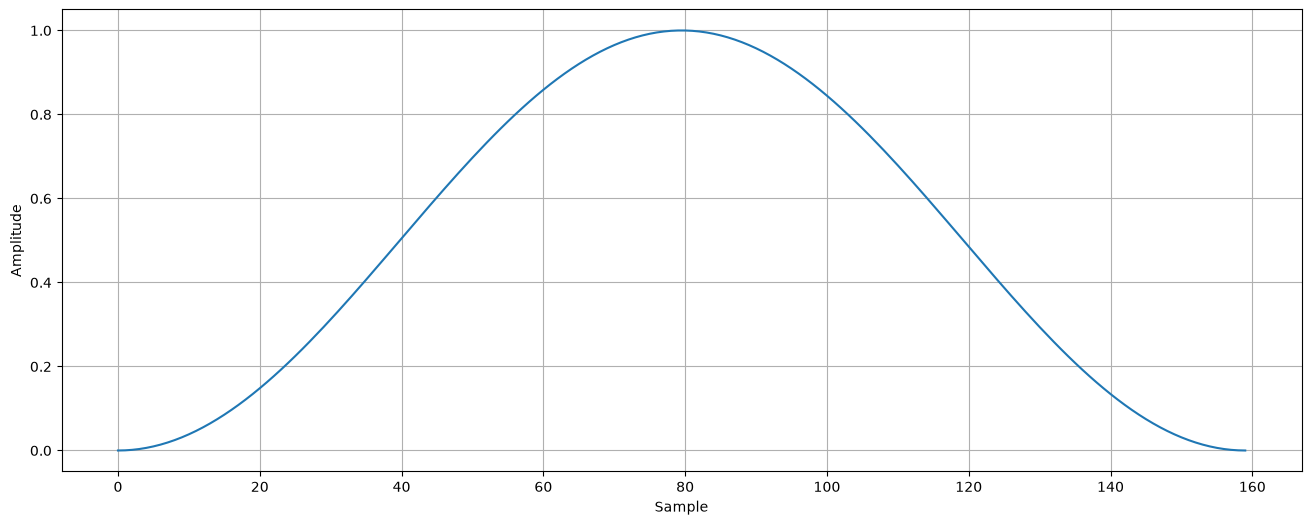

In [11]:
y              = audio_resample
frame_size     = int(0.020*fs) # Tamanho do frame
voice_size     = len(audio_resample)
n_windows      = int(2*voice_size/frame_size-1)
y_window       = np.zeros([n_windows,frame_size])
max_amp_frames = np.zeros([n_windows])
energy_frames  = np.zeros([n_windows])
window         = np.hanning(frame_size)

plt.figure(figsize=(16,6))
plot(window)
ylabel('Amplitude')
xlabel('Sample')
plt.grid(True)

In [12]:
for ii in range(n_windows):
      y_window[ii,:]     = y[ii*int(frame_size/2):frame_size+ii*int(frame_size/2)]*window # Janelando o sinal
      max_amp_frames[ii] = max(abs(y_window[ii,:])) # obtendo o valor da maior amplitude absoluta por frame
      energy_frames[ii]  = sum(y_window[ii,:]**2) # calculando a energia do frame

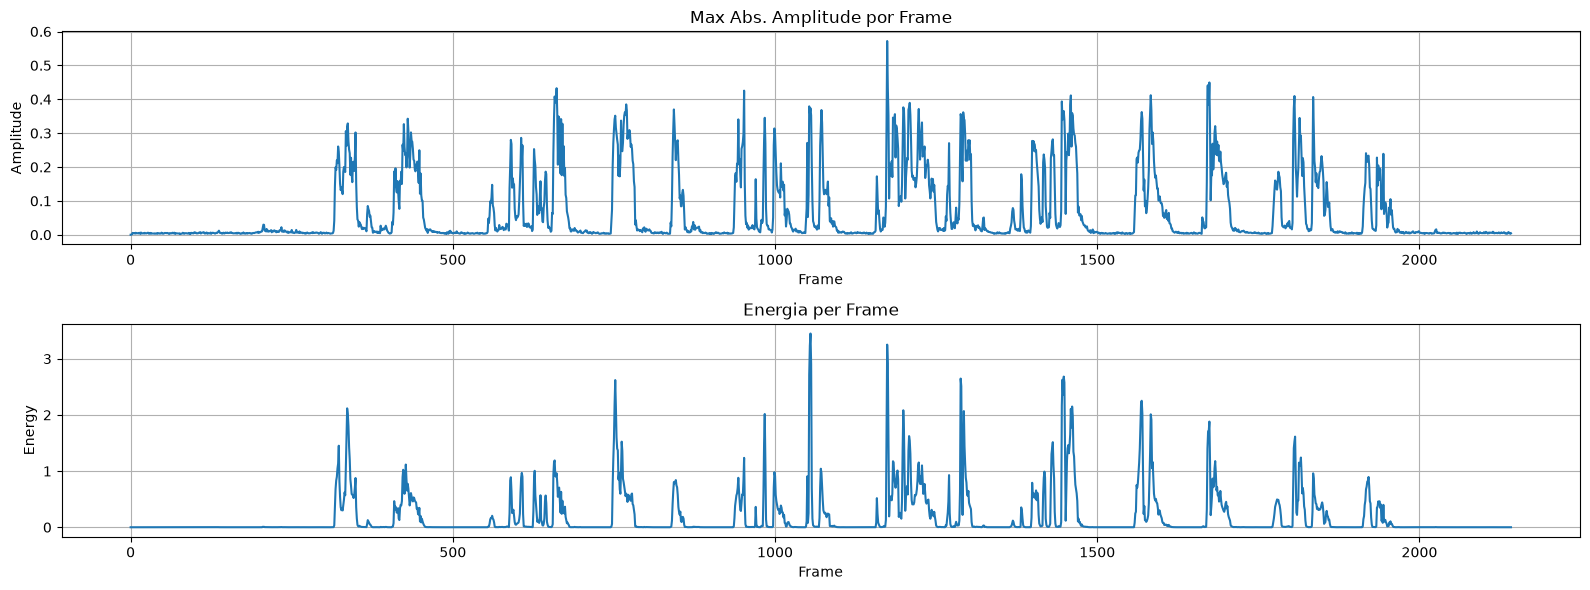

In [13]:
plt.figure(figsize=(16, 6))

plt.subplot(2, 1, 1)
plt.plot(max_amp_frames)
plt.title('Max Abs. Amplitude por Frame')
plt.ylabel('Amplitude')
plt.xlabel('Frame')
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(energy_frames)
plt.title('Energia per Frame')
plt.ylabel('Energy')
plt.xlabel('Frame')
plt.grid(True)

plt.tight_layout()
plt.show()

---

3. Classifique cada um dos trechos em "voz (1)" e "silêncio (0)" utilizando um VAD baseado em limiar de **energia**; Determine o valor "ótimo" deste limiar para o sinal que foi gravado.

Empiricamente, o valor ótimo encontrado para esse áudio nessa configuração foi 0.012. Foi possível observar que com números mais baixos, por exemplo 0.005 o VAD deixava passar trechos de ruído ambiente que não eram da voz.

In [14]:
audio_vad  = np.zeros([n_windows,frame_size])
frames_vad = np.zeros([n_windows,frame_size])
audio_aux  = np.zeros([n_windows])
max_lim    = 0.012 # Limiar de energia
kk         = 0
# VAD baseado em energia
for ii in range(n_windows):
    if energy_frames[ii] > max_lim:
      audio_vad[ii,:]  = y_window[ii,:]
      frames_vad[ii,:] = np.ones([frame_size])
      audio_aux[ii]    = 1
      kk = kk+1
    else:
      audio_vad[ii,:]  = np.zeros([frame_size])

In [15]:
z        = np.zeros([voice_size])
for ii in range(n_windows):
      z[ii*int(frame_size/2):frame_size+ii*int(frame_size/2)] = z[ii*int(frame_size/2):frame_size+ii*int(frame_size/2)] + audio_vad[ii,:]

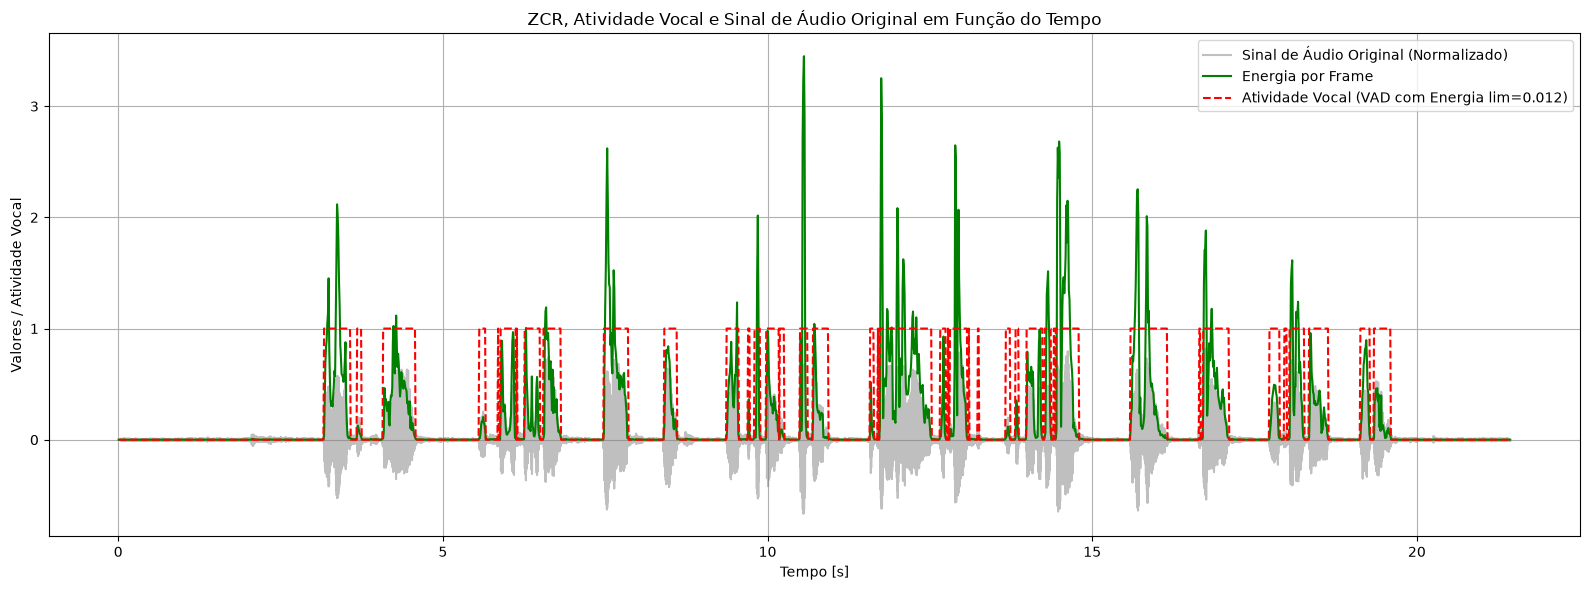

In [16]:
plt.figure(figsize=(16,6))

# Calculate time axis for frames
# Each frame starts at ii*int(frame_size/2) samples
# The center of the frame is at (start_sample + frame_size/2) samples
frame_time_centers = (np.arange(n_windows) * int(frame_size/2) + frame_size/2) / fs

# Plot original audio signal as a background overlay with transparency
# Normalize audio_resample to fit visually with ZCR and VAD line
scaled_audio = audio_resample / np.max(np.abs(audio_resample)) # Scale to max ZCR for visual alignment
plt.plot(t, scaled_audio, label='Sinal de Áudio Original (Normalizado)', alpha=0.5, color='gray')

# Plot Energy per frame
plt.plot(frame_time_centers, energy_frames, label='Energia por Frame', color='green')

# Plot VAD activity (scaled for visual alignment)
# The VAD output is either 0 or 1. Scaling it by zcr_lim makes it visible on the same plot.
plt.plot(frame_time_centers, audio_aux, label=f'Atividade Vocal (VAD com Energia lim={max_lim})', color='red', linestyle='--')

plt.title('ZCR, Atividade Vocal e Sinal de Áudio Original em Função do Tempo')
plt.ylabel('Valores / Atividade Vocal')
plt.xlabel('Tempo [s]')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
Audio(data=z, rate=fs) # Reproduzindo o sinal de voz na saída do VAD

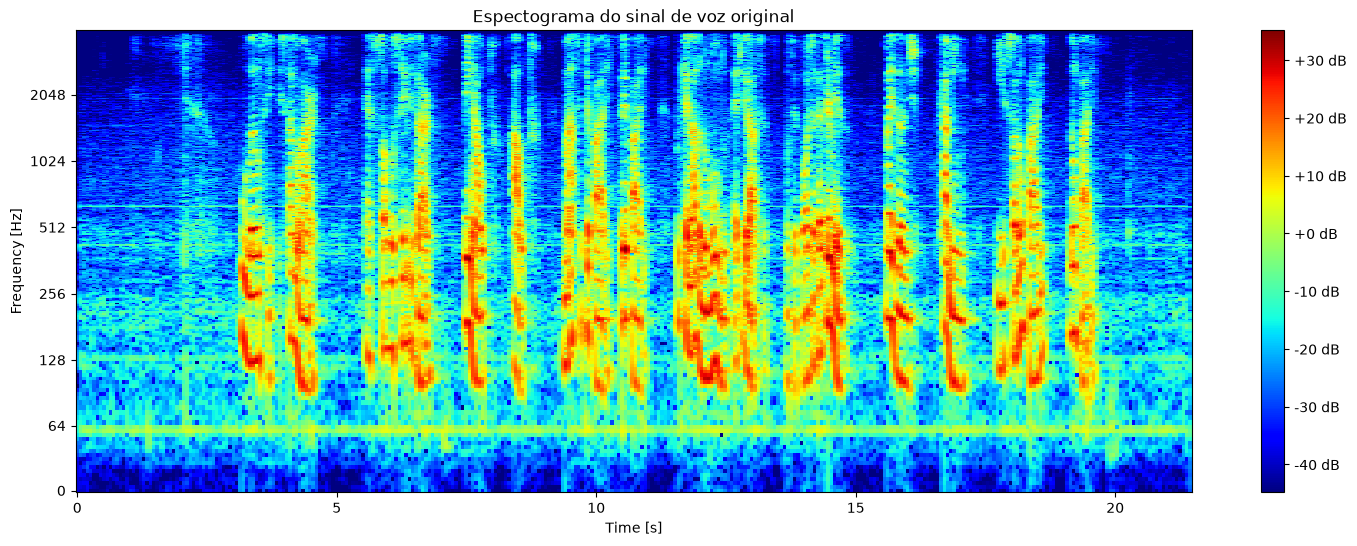

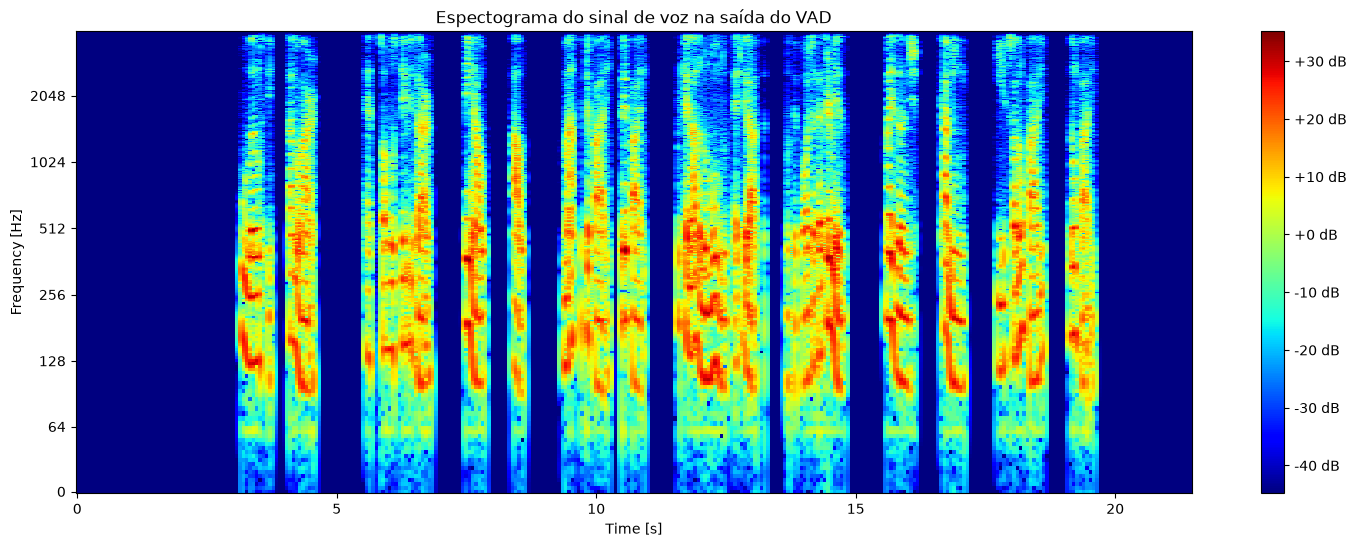

In [18]:
audio_stft_s = np.abs(librosa.stft(audio_resample))
audio_stft_z = np.abs(librosa.stft(z))

plt.figure(figsize=(18,6))
specshow(librosa.amplitude_to_db(audio_stft_s),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Espectograma do sinal de voz original')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.colorbar(format='%+2.0f dB')

plt.figure(figsize=(18,6))
specshow(librosa.amplitude_to_db(audio_stft_z),
         y_axis='log',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Espectograma do sinal de voz na saída do VAD')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.colorbar(format='%+2.0f dB')
plt.show()

---

4. O que acontece com o sinal na saída do VAD quando o valor do limiar utilizado é muito maior do que o valor obtido no item anterior?

Ao definir valores mais altos, o VAD passa a ser mais "agressivo", e classifica como voz apenas os trechos com fonemas de mais energia, como é o caso de sons vozeados. Fonemas não vozeados, por possuírem menor energia, acabam sendo classificados como silêncio. Inclusive, na própria configuração "ótima" adotada, alguns desses sons foram barrados. Perceptualmente, nós conseguimos entender o que está sendo dito pelo contexto, mas o som em si em alguns trechos, como ocorre no começo, em

O LAN[C]E [ES]TÁ NO AR

É [S]Ó VOCÊ GRITAR

BEM A[L][TO] A[L][TO]

é possível observar que os sons do "S", "T" (não vozeados) e até mesmo do "L" (vozeado, mas com baixa energia) são parcial ou totalmente recortado. Esse efeito é mais recorrente nos inícios e finais das palavras. Essa é uma limitação do VAD baseado exclusivamente em energia: ao aumentar o limiar ele classifica alguns trechos de voz como silêncio e ao diminuir, trechos com ruído de fundo passam a ser classificados como voz.

---

5. Qual a vantagem de se utilizar um VAD no processamento de um sinal de voz?

A principal vantagem é a capacidade de isolar os trechos de fala em um áudio, permitindo recortar trechos que não possuem voz, podendo ser silêncio ou mesmo ruídos de fundo. Isso possibilita implementar mecanismos para que, em um sistema de comunicação, por exemplo, o microfone só fique aberto durante o momento de fala, economizando banda e evitando vazamento de sons de ambiente. Além disso, o uso de VAD é quase que um pré-requisito em diversas tarefas que envolvem processamento de sinais de fala, como é o caso do reconhecimento automático de fala, reconhecimento de locutor, classificação de intenção, de emoção e quaisquer outras tarefas que podem ter a qualidade degradada se o sinal de voz processado pelo modelo não conter exclusivamente segmentos de voz.